In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### Se pide, usando regresión lineal:

Dibujar con una línea la relación que hay entre la altura y la edad de los alumnos de esta clase: 

In [4]:
lista_alumnos = [("Leonardo S", 24, 1.82), 
                 ("Piero T", 25, 1.71), 
                 ("Marta B", 35, 1.66), 
                 ("Silvia P", 37, 1.63), 
                 ("Faro Z", 29, 1.90), 
                 ("Miguel N", 27, 1.80), 
                 ("Alejandro M", 28, 1.70), 
                 ("Cristina M", 32, 1.60), 
                 ("Francisco P", 36, 1.74), 
                 ("Jorge D", 45, 1.72), 
                 ("Jesús L", 41, 1.65), 
                 ("Marta G", 30, 1.65), 
                 ("Jennifer S", 40, 1.60), 
                 ("Diego I", 39, 1.80), 
                 ("Antonio C", 23, 1.77), 
                 ("Juan M", 32, 1.75), 
                 ("David S", 27, 1.70), 
                 ("Antonio J", 34, 1.80), 
                 ("Carlos H", 27, 1.77), 
                 ("Erik U", 28, 1.70), 
                 ("Marcos L", 35, 1.80)] 

### ¿Es una buena técnica para este tipo de problemas? Demuéstralo antes de entrenar un modelo con un análisis descriptivo.

In [5]:
df = pd.DataFrame(lista_alumnos, columns=["nombre", "edad", "altura"])

In [6]:
df.head()

,nombre,edad,altura
0,Leonardo S,24,1.82
1,Piero T,25,1.71
2,Marta B,35,1.66
3,Silvia P,37,1.63
4,Faro Z,29,1.90


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   nombre  21 non-null     str    
 1   edad    21 non-null     int64  
 2   altura  21 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 636.0 bytes


In [8]:
df.describe()

,edad,altura
count,21.000000,21.000000
mean,32.095238,1.727143
std,6.081980,0.079003
min,23.000000,1.600000
25%,27.000000,1.660000
50%,32.000000,1.720000
75%,36.000000,1.800000
max,45.000000,1.900000


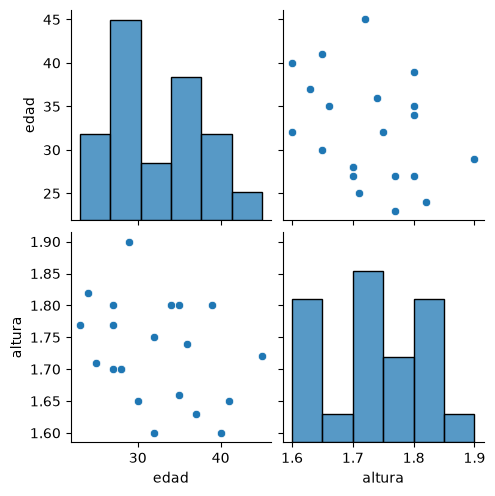

In [9]:
sns.pairplot(df);

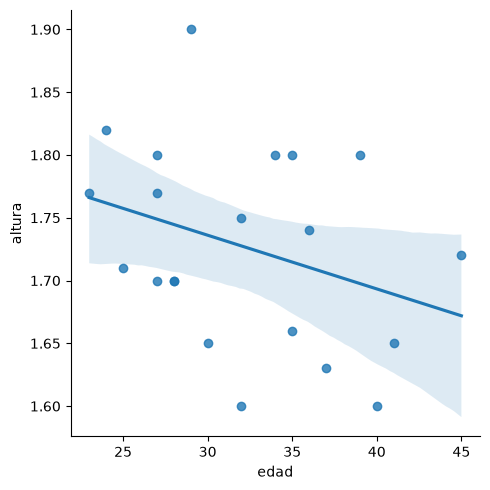

In [10]:
sns.lmplot(df, x = "edad", y= "altura")

no me parece la mejor opción, pero lo compro...

### Entrena un modelo de regresión lineal

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [12]:
#Getting all Column names
df.columns

Index(['nombre', 'edad', 'altura'], dtype='str')

In [13]:
X = df[["edad"]]
y = df["altura"]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 4, random_state = 42) # con test-size le digo que quiero 30 muestras

In [15]:
print("Total features shape:", X.shape)
print("Train features shape:", X_train.shape)
print("Train target shape:", y_train.shape)
print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Total features shape: (21, 1)
Train features shape: (17, 1)
Train target shape: (17,)
Test features shape: (4, 1)
Test target shape: (4,)


In [16]:
lm = LinearRegression()

In [17]:
#Training the Data Model
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['edad']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.854
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [18]:
print(lm.intercept_)

1.8538095697472503


In [19]:
print(lm.coef_) # cada año más que tienes de edad, la altura baja 0,004

[-0.00415879]


In [20]:
predictions = lm.predict(X_test)
predictions

array([1.75399865, 1.71241077, 1.72072834, 1.74983986])

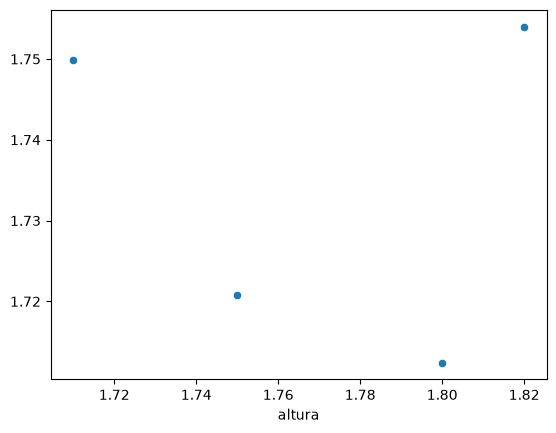

In [21]:
sns.scatterplot(x = y_test, y = predictions);

### ¿Qué error se comete? Calcula los errores que está cometiendo tu modelo de forma manual con python. Aparte, usa las métricas de sklearn MAE, MAPE, MSE y el RMSE.

In [22]:
df_2 = df

df_2["predictions"] = lm.predict(df_2[["edad"]])
df_2["error"] = df["altura"] - lm.predict(df_2[["edad"]])
df_2["error_cuadr"] = df_2["error"]**2
df_2

,nombre,edad,altura,predictions,error,error_cuadr
0,Leonardo S,24,1.82,1.753999,0.066001,0.004356
1,Piero T,25,1.71,1.749840,-0.039840,0.001587
2,Marta B,35,1.66,1.708252,-0.048252,0.002328
3,Silvia P,37,1.63,1.699934,-0.069934,0.004891
4,Faro Z,29,1.90,1.733205,0.166795,0.027821
5,Miguel N,27,1.80,1.741522,0.058478,0.003420
6,Alejandro M,28,1.70,1.737363,-0.037363,0.001396
7,Cristina M,32,1.60,1.720728,-0.120728,0.014575
8,Francisco P,36,1.74,1.704093,0.035907,0.001289
9,Jorge D,45,1.72,1.666664,0.053336,0.002845


In [65]:
from sklearn import metrics

lm.score(X_test, y_test)

-0.9556887365407665

In [68]:
print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))

MAE: 0.05567552575728363
MSE: 0.003618024162600424
RMSE: 0.060150013820450814
